# Weighted PageRank in Tennis — Part 2
**Chakib Madcur · Progress update**

What we agreed on 9/30:
1. Show **all the wins A has over B and B over A** on the graph
2. Apply the program to the **top 50 and top 100** players: is the correlation better?
3. Do the same for **2015**
4. Compare **Elo, ATP and PageRank**
5. Players with the **same ATP points**: what does PageRank say?

*(The half page on Elo for the paper is in a separate document.)*

## Step 1 · Setup
Same data and the same weighted PageRank program as last time, now written as functions so they can be reused for any season.

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

DATA = "https://raw.githubusercontent.com/Aneeshers/tennis-sackmann-archive/main/atp/"   # copy of Jeff Sackmann's data
ROUND_ORDER = {"R128": 1, "R64": 2, "R32": 3, "R16": 4, "RR": 5, "QF": 6, "SF": 7, "F": 8}

def load_season(year):
    m = pd.read_csv(DATA + f"atp_matches_{year}.csv")
    m = m[(m.tourney_level != "D") & (m.tourney_name != "Next Gen Finals")
          & (~m.score.astype(str).str.contains("W/O", na=False))].copy()
    m["round_order"] = m["round"].map(ROUND_ORDER)
    return m.sort_values(["tourney_date", "tourney_id", "round_order"])     # matches in the order they were played

def build_graph(m):
    G = nx.DiGraph()                                   # arrow: loser -> winner, weight = matches won
    for loser, winner in zip(m.loser_id, m.winner_id):
        if G.has_edge(loser, winner):
            G[loser][winner]["weight"] += 1
        else:
            G.add_edge(loser, winner, weight=1)
    return G

def weighted_pagerank(G, node_weight, d=0.85, rounds=100):
    total = sum(node_weight.values())
    share = {p: node_weight[p] / total for p in G}
    out = {p: G.out_degree(p, weight="weight") for p in G}
    score = {p: 1 / len(G) for p in G}
    for _ in range(rounds):
        new = {p: (1 - d) * share[p] for p in G}
        unbeaten = sum(score[p] for p in G if out[p] == 0)
        for p in G:
            new[p] += d * unbeaten * share[p]
        for loser, winner, w in G.edges(data="weight"):
            new[winner] += d * score[loser] * w / out[loser]
        score = new
    return score

def pagerank_ranks(m, G):
    wins = m.winner_id.value_counts()
    node_weight = {p: wins.get(p, 0) + 1 for p in G}          # node weight = matches won (+1)
    pr = weighted_pagerank(G, node_weight)
    return pd.Series(pr).rank(ascending=False, method="min").astype(int)

def atp_year_end(year):
    file = "atp_rankings_10s.csv" if year < 2020 else "atp_rankings_20s.csv"
    r = pd.read_csv(DATA + file)
    r = r[r.ranking_date == r[r.ranking_date <= year * 10000 + 1231].ranking_date.max()]
    return r.set_index("player")[["rank", "points"]]

m25 = load_season(2025)
G25 = build_graph(m25)
names = dict(zip(m25.winner_id, m25.winner_name)) | dict(zip(m25.loser_id, m25.loser_name))
pr25 = pagerank_ranks(m25, G25)
atp25 = atp_year_end(2025)
print(f"2025: {len(m25):,} matches, {G25.number_of_nodes()} players, {G25.number_of_edges()} edges")

2025: 2,655 matches, 292 players, 2395 edges


## Step 2 · All the wins A has over B, and B over A
Each arrow points to the winner, and the **number on the arrow is how many times that player won**. When two players beat each other, there are two arrows, one in each direction, each with its own number.

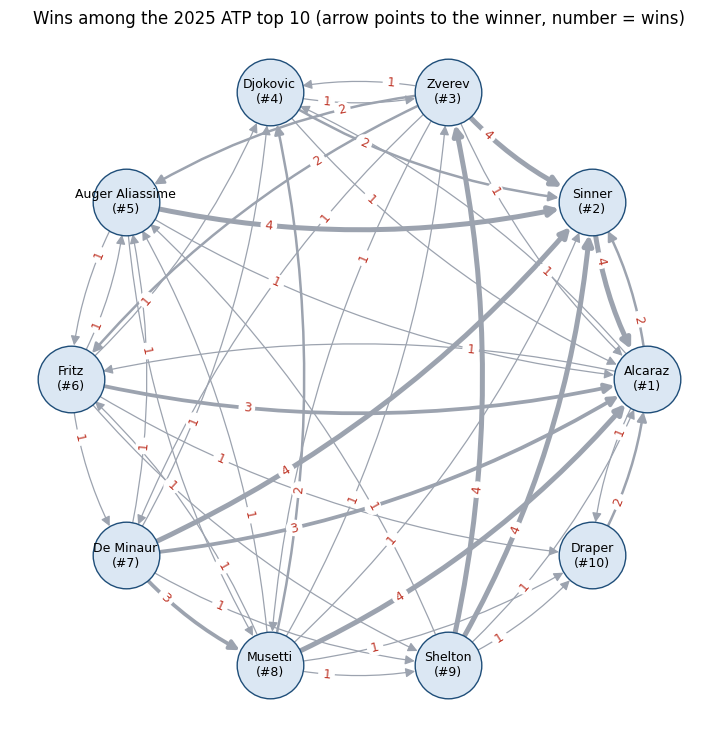

In [2]:
top10 = [p for p in G25 if atp25["rank"].get(p, 999) <= 10]
H = G25.subgraph(top10)
pos = nx.circular_layout(sorted(H, key=lambda p: atp25["rank"][p]))
short = {p: " ".join(names[p].split()[1:]) for p in H}
labels = {p: f"{short[p]}\n(#{atp25['rank'][p]})" for p in H}
style = "arc3,rad=0.12"

plt.figure(figsize=(9, 9))
nx.draw_networkx_nodes(H, pos, node_size=2300, node_color="#dbe7f3", edgecolors="#1f4e79")
nx.draw_networkx_labels(H, pos, labels, font_size=9)
nx.draw_networkx_edges(H, pos, width=[0.9 * H[u][v]["weight"] for u, v in H.edges()], edge_color="#9ca3af",
                       arrowsize=14, node_size=2300, connectionstyle=style)
nx.draw_networkx_edge_labels(H, pos, {(u, v): H[u][v]["weight"] for u, v in H.edges()}, connectionstyle=style,
                             font_size=9, font_color="#c0392b", label_pos=0.3,
                             bbox=dict(boxstyle="circle,pad=0.15", fc="white", ec="none"))
plt.title("Wins among the 2025 ATP top 10 (arrow points to the winner, number = wins)")
plt.axis("off"); plt.show()

The same information as a **head-to-head table**: read across a row to see how many times that player beat each opponent.

In [3]:
order = sorted(top10, key=lambda p: atp25["rank"][p])
h2h = pd.DataFrame(0, index=[short[p] for p in order], columns=[short[p] for p in order])
for winner in order:
    for loser in order:
        if G25.has_edge(loser, winner):
            h2h.loc[short[winner], short[loser]] = G25[loser][winner]["weight"]
h2h.index.name = "Winner ↓   Loser →"
h2h.style.background_gradient(cmap="Blues", vmin=0, vmax=4)

,Alcaraz,Sinner,Zverev,Djokovic,Auger Aliassime,Fritz,De Minaur,Musetti,Shelton,Draper
Winner ↓ Loser →,,,,,,,,,,
Alcaraz,0,4,1,1,1,3,3,4,1,2
Sinner,2,0,4,2,4,0,4,1,4,0
Zverev,0,0,0,1,0,0,0,1,4,0
Djokovic,1,0,1,0,0,1,1,2,0,0
Auger Aliassime,0,0,2,0,0,1,1,1,1,0
Fritz,1,0,2,0,1,0,0,1,0,0
De Minaur,0,0,1,0,0,1,0,0,0,0
Musetti,0,0,1,0,1,0,3,0,0,0
Shelton,0,0,0,0,0,1,1,1,0,0


## Step 3 · The Elo rating
Elo (originally from chess) gives every player a rating that goes up after a win and down after a loss. Beating a stronger player earns more than beating a weaker one. I use the tennis version of the formula (Kovalchik, 2016): everyone starts at 1500, and ratings move less as a player plays more matches.

- Expected chance that A beats B: **1 / (1 + 10^((Elo_B − Elo_A) / 400))**
- After the match: **Elo_A ← Elo_A + K × (result − expected)**, with **K = 250 / (matches played + 5)^0.4**

Elo needs history, so I run it on every tour-level match from 2005 onward and save the ratings at the end of 2015 and 2025.

In [4]:
def run_elo(first_year, last_year, save_years):
    rating, played, saved = {}, {}, {}
    for year in range(first_year, last_year + 1):
        m = load_season(year)
        for w, l in zip(m.winner_id, m.loser_id):
            rw, rl = rating.get(w, 1500), rating.get(l, 1500)
            expected = 1 / (1 + 10 ** ((rl - rw) / 400))           # chance the winner had of winning
            rating[w] = rw + 250 / (played.get(w, 0) + 5) ** 0.4 * (1 - expected)
            rating[l] = rl - 250 / (played.get(l, 0) + 5) ** 0.4 * (1 - expected)
            played[w] = played.get(w, 0) + 1;  played[l] = played.get(l, 0) + 1
        if year in save_years:
            saved[year] = pd.Series(rating)
    return saved

elo = run_elo(2005, 2025, save_years=[2015, 2025])
elo25 = elo[2025][list(G25)].rank(ascending=False, method="min").astype(int)      # Elo rank among 2025 players

pd.DataFrame({"Player": [names[p] for p in elo[2025][list(G25)].nlargest(10).index],
              "Elo": elo[2025][list(G25)].nlargest(10).round().astype(int).values,
              "ATP rank": [atp25["rank"].get(p) for p in elo[2025][list(G25)].nlargest(10).index]}).rename(lambda i: i + 1)

,Player,Elo,ATP rank
1,Jannik Sinner,2339,2
2,Carlos Alcaraz,2280,1
3,Novak Djokovic,2187,4
4,Jack Draper,2053,10
5,Alexander Zverev,2023,3
6,Taylor Fritz,2020,6
7,Alex De Minaur,2011,7
8,Felix Auger Aliassime,1990,5
9,Arthur Fils,1968,39
10,Grigor Dimitrov,1956,44


## Step 4 · Top 10, top 50, top 100 — PageRank vs ATP vs Elo (2025)
For the ATP top 10, 50 and 100, I measure how similar each ranking is to the others (Spearman correlation: 1.00 = identical order).

Two ways to apply the program to N players:
- **Full graph:** PageRank uses the whole season (all 292 players), then I compare the top N
- **Only top-N graph:** the graph is built only from matches *between* the top N players

In [5]:
def compare(m, G, pr, elo_rank, atp):
    rows = {}
    for N in [10, 50, 100]:
        top = [p for p in G if atp["rank"].get(p, 999) <= N]
        atp_r = atp["rank"][top]
        sub = m[m.winner_id.isin(top) & m.loser_id.isin(top)]           # only matches between the top N
        pr_sub = pagerank_ranks(sub, build_graph(sub))
        rows[f"Top {N}"] = {"PageRank vs ATP (full graph)":   atp_r.corr(pr[top], method="spearman"),
                            "PageRank vs ATP (only top-N graph)": atp_r.corr(pr_sub[top], method="spearman"),
                            "Elo vs ATP":                     atp_r.corr(elo_rank[top], method="spearman"),
                            "PageRank vs Elo":                pr[top].corr(elo_rank[top], method="spearman")}
    return pd.DataFrame(rows).T.round(2)

compare(m25, G25, pr25, elo25, atp25)

,PageRank vs ATP (full graph),PageRank vs ATP (only top-N graph),Elo vs ATP,PageRank vs Elo
Top 10,0.89,0.68,0.67,0.78
Top 50,0.87,0.83,0.72,0.69
Top 100,0.92,0.90,0.79,0.84


**The ATP top 10 of 2025 in each system:**

In [6]:
def top10_table(G, pr, elo_rank, atp):
    top = atp[atp["rank"] <= 10].index
    return pd.DataFrame({"Player": [names.get(p) for p in top], "ATP": atp["rank"][top].values,
                         "PageRank": pr[top].values, "Elo": elo_rank[top].values}).set_index("ATP")

top10_table(G25, pr25, elo25, atp25)

,Player,PageRank,Elo
ATP,,,
1,Carlos Alcaraz,1,2
2,Jannik Sinner,2,1
3,Alexander Zverev,4,5
4,Novak Djokovic,5,3
5,Felix Auger Aliassime,7,8
6,Taylor Fritz,3,6
7,Alex De Minaur,8,7
8,Lorenzo Musetti,12,11
9,Ben Shelton,18,17


## Step 5 · The same analysis for 2015

In [7]:
m15 = load_season(2015)
G15 = build_graph(m15)
names |= dict(zip(m15.winner_id, m15.winner_name)) | dict(zip(m15.loser_id, m15.loser_name))
pr15 = pagerank_ranks(m15, G15)
atp15 = atp_year_end(2015)
elo15 = elo[2015][list(G15)].rank(ascending=False, method="min").astype(int)
print(f"2015: {len(m15):,} matches, {G15.number_of_nodes()} players, {G15.number_of_edges()} edges")

compare(m15, G15, pr15, elo15, atp15)

2015: 2,621 matches, 282 players, 2304 edges


,PageRank vs ATP (full graph),PageRank vs ATP (only top-N graph),Elo vs ATP,PageRank vs Elo
Top 10,0.98,0.84,0.93,0.95
Top 50,0.85,0.80,0.88,0.83
Top 100,0.93,0.93,0.90,0.91


In [8]:
top10_table(G15, pr15, elo15, atp15)

,Player,PageRank,Elo
ATP,,,
1,Novak Djokovic,1,1
2,Andy Murray,3,3
3,Roger Federer,2,2
4,Stan Wawrinka,4,5
5,Rafael Nadal,5,4
6,Tomas Berdych,7,9
7,David Ferrer,10,8
8,Kei Nishikori,8,6
9,Richard Gasquet,11,10


## Step 6 · Same ATP points, different players
The ATP ranking only counts points, so two players can finish with exactly the same total. PageRank looks at **who they beat**, so it can tell them apart.

In [9]:
def same_points(atp, pr, elo_rank, m):
    top = atp[atp["rank"] <= 100]
    tied = top[top.duplicated("points", keep=False)].sort_values("rank")
    tied = tied[tied.index.isin(pr.index)]
    wins, losses = m.winner_id.value_counts(), m.loser_id.value_counts()
    return pd.DataFrame({"Player": [names.get(p) for p in tied.index], "ATP points": tied.points.values,
                         "ATP rank": tied["rank"].values, "PageRank": pr[tied.index].values,
                         "Elo": elo_rank[tied.index].values,
                         "W-L": [f"{wins.get(p, 0)}-{losses.get(p, 0)}" for p in tied.index]})

print("2025"); display(same_points(atp25, pr25, elo25, m25))
print("2015"); display(same_points(atp15, pr15, elo15, m15))

2025


,Player,ATP points,ATP rank,PageRank,Elo,W-L
0,Brandon Nakashima,1380,35,29,53,32-29
1,Stefanos Tsitsipas,1380,36,46,31,21-17
2,Alexei Popyrin,1000,53,61,52,17-23
3,Fabian Marozsan,1000,54,50,49,25-24
4,Hubert Hurkacz,765,72,58,20,15-11
5,Marin Cilic,765,73,74,42,8-11
6,Pedro Martinez,668,92,81,176,14-27
7,Pablo Carreno Busta,668,93,121,58,7-12
8,Alexander Shevchenko,652,97,97,92,11-19
9,Laslo Djere,652,98,86,96,13-13


2015


,Player,ATP points,ATP rank,PageRank,Elo,W-L
0,Ivo Karlovic,1485.0,23,6,28,38-25
1,Gael Monfils,1485.0,24,15,18,33-18
2,Grigor Dimitrov,1360.0,28,17,20,32-22
3,Andreas Seppi,1360.0,29,18,39,25-24
4,Thomaz Bellucci,1105.0,37,51,47,29-27
5,Gilles Muller,1105.0,38,29,34,31-24
6,Lukas Rosol,797.0,55,56,55,19-28
7,Victor Estrella,797.0,56,69,83,15-19


## Step 7 · Which ranking is more adequate?
A simple test: use each ranking at the end of the season to predict the winner of every match in the **first half of the next season** (the higher-ranked player is predicted to win).

In [10]:
def predict_next(year, pr, elo_scores, atp):
    nxt = load_season(year + 1)
    nxt = nxt[nxt.tourney_date <= (year + 1) * 10000 + 630]                 # January - June
    ok = lambda p: p in pr.index and p in atp.index and p in elo_scores.index
    games = [(w, l) for w, l in zip(nxt.winner_id, nxt.loser_id) if ok(w) and ok(l)]
    return {"Matches": len(games),
            "ATP ranking": np.mean([atp["rank"][w] < atp["rank"][l] for w, l in games]),
            "Elo": np.mean([elo_scores[w] > elo_scores[l] for w, l in games]),
            "Weighted PageRank": np.mean([pr[w] < pr[l] for w, l in games])}

res = pd.DataFrame({"2015 → first half 2016": predict_next(2015, pr15, elo[2015], atp15),
                    "2025 → first half 2026": predict_next(2025, pr25, elo[2025], atp25)}).T
res["Matches"] = res["Matches"].astype(int)
res.style.format({"ATP ranking": "{:.1%}", "Elo": "{:.1%}", "Weighted PageRank": "{:.1%}"})

,Matches,ATP ranking,Elo,Weighted PageRank
2015 → first half 2016,1509,67.1%,67.7%,66.8%
2025 → first half 2026,1202,63.7%,64.9%,63.6%


## Findings
1. **Head-to-head:** the graph now shows every result in both directions. For example, Alcaraz beat Sinner 4 times and Sinner beat Alcaraz 2 times in 2025.
2. **Top 10 vs 50 vs 100:** when the graph only contains the top N players, the correlation with ATP **improves as N grows** (2025: 0.68 → 0.83 → 0.90). More players means more matches and more information for PageRank. Using the full-season graph, PageRank already agrees strongly with ATP at every level (0.87–0.92 in 2025).
3. **2015 gives the same picture:** PageRank vs ATP 0.98 (top 10), 0.85 (top 50), 0.93 (top 100).
4. **PageRank is closer to the ATP ranking than Elo is**, especially in 2025. Elo is built on a player's whole career and does not drop players who stop competing: Arthur Fils is 9th in Elo but 39th in the ATP (he played no tour-level matches after July 2025), because ATP points expire after 52 weeks.
5. **Same points, different players:** in 2025, Nakashima and Tsitsipas both finished with 1,380 points, but PageRank ranks Nakashima 29th and Tsitsipas 46th. Nakashima won more matches (32–29 vs 21–17) and beat a top-20 player. In 2015, Karlovic and Monfils both had 1,485 points; PageRank puts Karlovic 6th because he beat Djokovic, Wawrinka and Berdych.
6. **Prediction:** all three systems predict the next season about equally well (64–68%); Elo is slightly ahead in both years, and PageRank and ATP are almost identical. PageRank matches the official ranking using **only who beat whom in one season**, without any points table, and it adds information the ATP cannot give (it separates players with equal points).

**Next steps we discussed (to prepare, not done yet)**
- Mid-November: a title and a short presentation
- Compare the rankings through time (several seasons, e.g. the top 100 over the years)